# Lab 4 · Online machine learning on data streams

Adam Chgour · M2 Data Science · Institut Polytechnique de Paris

This notebook contains the data loaders, online models, evaluation loops, and plots. The saved outputs correspond to the accompanying LaTeX PDF.

To reproduce the run, use a fresh Python 3.12 Jupyter kernel with a JDK. The recorded run used OpenJDK 17. Install the following packages in the kernel if needed, then restart it and run all cells. The public UCI archives download on first use. New result tables and figures are saved under `lab4_run/`.

```python
%pip install river==0.23.0 capymoa==0.15.0 numpy==2.5.5 pandas==2.3.3 scipy==1.18.1 scikit-learn==1.9.1 jpype1==1.7.1 psutil==7.2.2 matplotlib==3.11.2
```

In [1]:
import os
from pathlib import Path

for variable in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[variable] = "1"

import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display

RUN_DIR = Path("lab4_run")
RESULTS = RUN_DIR / "results"
FIGURES = RUN_DIR / "figures"
DATA_DIR = Path(os.environ.get("LAB_DATA_DIR", ".data"))

pd.options.display.float_format = "{:,.4f}".format

## 1. Data

Seoul bike rentals, appliance energy, and highway traffic are next-interval forecasts. Only adjacent intervals form a pair; features use the preceding observations and the upcoming interval's known calendar. Occupancy and EEG retain time order. Gas sensor batches come in dated order, with each batch shuffled using seed 42. Synthetic Friedman and SEA replays shift at row 5,001.

In [2]:
import shutil
from gzip import GzipFile
from io import TextIOWrapper
from tempfile import NamedTemporaryFile
from urllib.request import urlopen
from zipfile import ZipFile

from scipy.io import arff

UCI = "https://archive.ics.uci.edu/static/public"
ARCHIVES = {
    "seoul": "560/seoul+bike+sharing+demand.zip",
    "appliances": "374/appliances+energy+prediction.zip",
    "traffic": "492/metro+interstate+traffic+volume.zip",
    "occupancy": "357/occupancy+detection.zip",
    "eeg": "264/eeg+eye+state.zip",
    "gas": "224/gas+sensor+array+drift+dataset.zip",
}
OCCUPANCY_FEATURES = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]


def archive(key):
    folder = DATA_DIR
    path = folder / f"{key}.zip"
    if not path.exists():
        folder.mkdir(parents=True, exist_ok=True)
        with NamedTemporaryFile(dir=folder, delete=False) as temp:
            downloaded = Path(temp.name)
            try:
                with urlopen(f"{UCI}/{ARCHIVES[key]}", timeout=60) as response:
                    shutil.copyfileobj(response, temp)
                temp.flush()
                with ZipFile(downloaded):
                    pass
                downloaded.replace(path)
            finally:
                downloaded.unlink(missing_ok=True)
    return ZipFile(path)


def records(features, target):
    names = tuple(features.columns)
    for values, label in zip(features.itertuples(index=False, name=None), target, strict=True):
        yield dict(zip(names, values, strict=True)), label


def next_interval(frame, target, feature_names, interval_minutes, limit=None):
    """Forecast the next adjacent interval from current observations and its calendar."""
    ordered = frame.sort_values("time", kind="stable").drop_duplicates("time")
    target_time = ordered.time.shift(-1)
    contiguous = (target_time - ordered.time) == np.timedelta64(interval_minutes, "m")
    observed = ordered.loc[contiguous]
    times = target_time.loc[contiguous].dt
    hour = times.hour + times.minute / 60
    features = observed[feature_names].copy()
    features["lag_target"] = observed[target]
    for name, angle in (("hour", 2 * np.pi * hour / 24),
                        ("weekday", 2 * np.pi * times.dayofweek / 7)):
        features[f"{name}_sin"] = np.sin(angle)
        features[f"{name}_cos"] = np.cos(angle)
    return records(features.iloc[:limit], ordered[target].shift(-1).loc[contiguous].iloc[:limit])

In [3]:
def seoul_bikes():
    with archive("seoul") as z, z.open("SeoulBikeData.csv") as f:
        frame = pd.read_csv(f, encoding="latin-1")
    frame["time"] = pd.to_datetime(frame["Date"], format="%d/%m/%Y") + pd.to_timedelta(frame.Hour, unit="h")
    weather = [
        "Temperature(°C)", "Humidity(%)", "Wind speed (m/s)", "Visibility (10m)",
        "Dew point temperature(°C)", "Solar Radiation (MJ/m2)", "Rainfall(mm)", "Snowfall (cm)",
    ]
    return next_interval(frame, "Rented Bike Count", weather, 60)


def appliance_energy():
    with archive("appliances") as z, z.open("energydata_complete.csv") as f:
        frame = pd.read_csv(f)
    frame["time"] = pd.to_datetime(frame.date)
    sensors = ["lights", "T1", "RH_1", "T2", "RH_2", "T3", "RH_3"]
    return next_interval(frame, "Appliances", sensors, 10)


def metro_traffic():
    with archive("traffic") as z, z.open("Metro_Interstate_Traffic_Volume.csv.gz") as f:
        with GzipFile(fileobj=f) as uncompressed:
            frame = pd.read_csv(uncompressed)
    frame["time"] = pd.to_datetime(frame.date_time)
    # Zero Kelvin in this file means an invalid observation, not a temperature.
    frame = frame.loc[frame.temp.between(200, 330)].copy()
    frame["raining"] = (frame.rain_1h > 0).astype(int)
    frame["snowing"] = (frame.snow_1h > 0).astype(int)
    sensors = ["temp", "clouds_all", "raining", "snowing"]
    return next_interval(frame, "traffic_volume", sensors, 60, limit=12_000)

In [4]:
def occupancy_frame():
    chunks = []
    with archive("occupancy") as z:
        for name in ("datatest.txt", "datatraining.txt", "datatest2.txt"):
            with z.open(name) as f:
                chunks.append(pd.read_csv(f, index_col=0, parse_dates=["date"]))
    return pd.concat(chunks, ignore_index=True).sort_values("date", kind="stable")


def occupancy():
    frame = occupancy_frame()
    return records(frame[OCCUPANCY_FEATURES], frame.Occupancy)


def occupancy_clustering():
    frame = occupancy_frame().iloc[:6000]
    # Express light in hundreds of lux and CO2 in units of 250 ppm.
    return frame[["Light", "CO2"]].to_numpy() / [100., 250.], frame.Occupancy.to_numpy()


def eeg_eye_state():
    with archive("eeg") as z, z.open("EEG Eye State.arff") as f:
        observations, _ = arff.loadarff(TextIOWrapper(f, encoding="ascii"))
    frame = pd.DataFrame(observations)
    return records(frame.drop(columns="eyeDetection"), frame.eyeDetection.astype(int))


def gas_sensor_drift(seed):
    rng = np.random.default_rng(seed)
    response_indices = range(2, 129, 8)  # Normalized steady-state response of each sensor.
    labels = {"1": 0, "5": 1}  # Ethanol vs acetone.
    with archive("gas") as z:
        for batch in range(1, 11):
            observations = []
            with z.open(f"Dataset/batch{batch}.dat") as f:
                for line in f:
                    label, *values = line.decode("ascii").split()
                    if label in labels:
                        full = dict(entry.split(":") for entry in values)
                        x = {f"sensor_{i}": float(full[str(index)])
                             for i, index in enumerate(response_indices, 1)}
                        observations.append((x, labels[label]))
            # The archive groups measurements by gas. Mix within each dated batch;
            # the order of batches, and hence the long-term drift, is preserved.
            for i in rng.permutation(len(observations)):
                yield observations[i]

In [5]:
SEED = 42
SWITCH = 5001  # 1-based first changed observation
SYNTH_SIZE = 10_000
REGRESSION = ("SeoulBikes", "ApplianceEnergy", "MetroTraffic", "FriedmanShift")
CLASSIFICATION = ("Occupancy", "EEGEyeState", "GasSensorDrift", "SEAShift")


def friedman():
    rng = np.random.default_rng(SEED)
    for i, x in enumerate(rng.random((SYNTH_SIZE, 10)), start=1):
        a, b, c, d, e = x[:5] if i < SWITCH else x[5:]
        y = 10 * np.sin(np.pi * a * b) + 20 * (c - .5) ** 2 + 10 * d + 5 * e
        y += (12 if i >= SWITCH else 0) + rng.normal()
        yield dict(enumerate(x)), y


def sea():
    rng = np.random.default_rng(SEED)
    for i, x in enumerate(rng.uniform(0, 10, size=(SYNTH_SIZE, 3)), start=1):
        threshold = 8 if i < SWITCH else 13
        y = int(x[0] + x[1] > threshold)
        if rng.random() < .05:
            y ^= 1
        yield dict(enumerate(x)), y

In [6]:
def load_rows(name):
    sources = {
        "SeoulBikes": seoul_bikes,
        "ApplianceEnergy": appliance_energy,
        "MetroTraffic": metro_traffic,
        "Occupancy": occupancy,
        "EEGEyeState": eeg_eye_state,
        "GasSensorDrift": lambda: gas_sensor_drift(SEED),
        "FriedmanShift": friedman,
        "SEAShift": sea,
    }
    rows = [({str(k): float(v) for k, v in x.items()}, y) for x, y in sources[name]()]
    if name in CLASSIFICATION:
        rows = [(x, int(y)) for x, y in rows]
    return rows


def prior_scaled(rows):
    """Transform x using statistics from observations 1 through t-1."""
    scaler = preprocessing.StandardScaler()
    for x, y in rows:
        yield scaler.transform_one(x), y
        scaler.learn_one(x)


def clustering_rows(moving):
    """Three isotropic Gaussian groups. Shift every center at observation 3001."""
    rng = np.random.default_rng(SEED)
    centers = np.array([[0., 0.], [0., 3.], [3., 0.]])
    shift = np.array([[-2., 1.], [3., 1.], [1., -2.]])
    labels = rng.integers(0, len(centers), 6000)
    x = centers[labels] + rng.normal(0, .30, size=(len(labels), 2))
    if moving:
        x[3000:] += shift[labels[3000:]]
    return x, labels

## 2. River models and evaluation protocol

The prequential loop predicts with the current model, then trains on that row. A regression detector receives scaled absolute error; a classification detector receives 0/1 error. Monitor runs record alarms. Reset runs replace the tree after scoring the alarm row, then learn from that row with the fresh tree.

In [7]:
from river import drift, forest, linear_model, naive_bayes, neighbors, optim, preprocessing, tree


def regression_models(seed):
    return {
        "HT": lambda: tree.HoeffdingTreeRegressor(grace_period=100, leaf_prediction="mean"),
        "ARF": lambda: forest.ARFRegressor(
            n_models=5, grace_period=100, leaf_prediction="mean", seed=seed,
        ),
        "AdaGrad": lambda: preprocessing.TargetStandardScaler(
            regressor=linear_model.LinearRegression(
                optimizer=optim.AdaGrad(.10), intercept_lr=.05,
            ),
        ),
        "kNN": lambda: neighbors.KNNRegressor(
            n_neighbors=5, engine=neighbors.LazySearch(window_size=200), aggregation_method="mean",
        ),
    }


def river_classification_models(seed):
    return {
        "HT": lambda: tree.HoeffdingTreeClassifier(
            grace_period=100, delta=1e-5, tau=.05, leaf_prediction="mc",
        ),
        "ARF": lambda: forest.ARFClassifier(
            n_models=5, max_features="sqrt", lambda_value=6, grace_period=100,
            delta=1e-5, tau=.05, leaf_prediction="mc", seed=seed,
        ),
        "Logistic": lambda: linear_model.LogisticRegression(
            optimizer=optim.AdaGrad(.05), intercept_lr=.05,
        ),
        "GaussianNB": naive_bayes.GaussianNB,
    }


def detectors(task):
    adwin = lambda: drift.ADWIN(delta=.002)
    if task == "regression":
        return {
            "ADWIN": adwin,
            "PageHinkley": lambda: drift.PageHinkley(min_instances=30, delta=.005, threshold=25, mode="up"),
            "KSWIN": lambda: drift.KSWIN(alpha=.005, window_size=100, stat_size=30, seed=42),
        }
    return {
        "ADWIN": adwin,
        "DDM": drift.binary.DDM,
        "EDDM": drift.binary.EDDM,
        "HDDM_A": drift.binary.HDDM_A,
    }

In [8]:
import csv
import gc
import platform
import subprocess
from importlib.metadata import version
from statistics import median
from time import perf_counter_ns

import psutil
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


PROCESS = psutil.Process()
REPEATS = 3
BLOCK = 250
RSS_INTERVAL = 250
DETECTOR_START = 101
DELAY_HORIZON = 1000


def write_table(name, rows):
    RESULTS.mkdir(parents=True, exist_ok=True)
    with (RESULTS / f"{name}.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]), lineterminator="\n")
        writer.writeheader()
        writer.writerows(rows)


def regression_scores(y, pred):
    return {
        "mae": mean_absolute_error(y, pred),
        "rmse": np.sqrt(mean_squared_error(y, pred)),
        "r2": r2_score(y, pred),
    }


def classification_scores(y, pred):
    return {
        "accuracy": accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, labels=[0, 1], average="macro", zero_division=0),
        "kappa": cohen_kappa_score(y, pred, labels=[0, 1]),
    }

In [9]:
def measure(rows, factory, task, detector=None, reset=False, scale=1., capy=False):
    """Time input-independent prediction, optional drift handling and update."""
    gc.collect()
    rss_start = PROCESS.memory_info().rss
    rss_peak = rss_start
    model = factory()
    predict, train = (model.predict, model.train) if capy else (model.predict_one, model.learn_one)
    latencies = np.empty(len(rows))
    predictions = np.empty(len(rows))
    alarms = []
    start = perf_counter_ns()

    for i, (x, y) in enumerate(rows, start=1):
        tick = perf_counter_ns()
        pred = predict(x)
        if pred is None:
            pred = 0

        if detector is not None and i >= DETECTOR_START:
            loss = min(1., abs(y - pred) / scale) if task == "regression" else int(y != pred)
            detector.update(loss)
            if detector.drift_detected:
                alarms.append(i)
                if reset:
                    model = factory()
                    predict, train = model.predict_one, model.learn_one

        if capy:
            train(x)
        else:
            train(x, y)
        latencies[i - 1] = (perf_counter_ns() - tick) / 1e3
        predictions[i - 1] = pred
        if i % RSS_INTERVAL == 0:
            rss_peak = max(rss_peak, PROCESS.memory_info().rss)

    elapsed = (perf_counter_ns() - start) / 1e9
    rss_peak = max(rss_peak, PROCESS.memory_info().rss)
    cost = {
        "wall_s": elapsed,
        "mean_us": latencies.mean(),
        "p95_us": np.quantile(latencies, .95),
        "rss_start_mib": rss_start / 2**20,
        "rss_peak_mib": rss_peak / 2**20,
        "rss_growth_mib": (rss_peak - rss_start) / 2**20,
    }
    return predictions, cost, alarms


def score_blocks(y, pred, task, identifiers):
    loss = abs(y - pred) if task == "regression" else (y == pred)
    return [
        identifiers | {"end": min(i + BLOCK, len(y)), "score": loss[i:i + BLOCK].mean()}
        for i in range(0, len(y), BLOCK)
    ]

In [10]:
def analyze_drift(task, name, inputs, y, baseline, factory, typical, summary, events, blocks):
    scores = regression_scores if task == "regression" else classification_scores
    main_metric = "mae" if task == "regression" else "accuracy"
    scale = max(3 * np.std(y[:100]), 1e-8)
    has_switch = name.endswith("Shift")
    post = slice(SWITCH - 1, SWITCH - 1 + DELAY_HORIZON)

    conditions = [("None", "baseline", baseline, typical, [])]
    for detector, make_detector in detectors(task).items():
        for policy in ("monitor", "reset"):
            pred, cost, alarms = measure(
                inputs, factory, task, detector=make_detector(),
                reset=(policy == "reset"), scale=scale,
            )
            if policy == "monitor" and not np.array_equal(pred, baseline):
                raise RuntimeError("Monitor-only condition changed model predictions.")
            conditions.append((detector, policy, pred, cost, alarms))

    for detector, policy, pred, cost, alarms in conditions:
        timely = [p for p in alarms if SWITCH <= p < SWITCH + DELAY_HORIZON] if has_switch else []
        identifiers = {"stream": name, "detector": detector, "policy": policy}
        summary.append(identifiers | {
            "n": len(y), "alarms": len(alarms),
            "pre_change_alarms": sum(p < SWITCH for p in alarms) if has_switch else "",
            "delay": timely[0] - SWITCH if timely else "",
            "first_1000_after": scores(y[post], pred[post])[main_metric] if has_switch else "",
            "score": scores(y, pred)[main_metric],
            "wall_s": cost["wall_s"], "mean_us": cost["mean_us"], "p95_us": cost["p95_us"],
        })
        events.extend(identifiers | {"position": p} for p in alarms)
        blocks.extend(score_blocks(y, pred, task, identifiers))

In [11]:
def evaluate(task, library):
    names = REGRESSION if task == "regression" else CLASSIFICATION
    scores = regression_scores if task == "regression" else classification_scores
    summary, timings, blocks = [], [], []
    drift_summary, drift_events, drift_blocks = [], [], []
    capy = library == "CapyMOA"

    for name in names:
        rows = load_rows(name)
        y = np.array([target for _, target in rows])
        scaled = list(prior_scaled(rows))
        print(f"{library} {task} {name}, n={len(rows)}", flush=True)
        if capy:
            feature_names = tuple(rows[0][0])
            schema = classification_schema(rows, name)
            factories = capy_classification_models(schema, SEED, len(feature_names))
        elif task == "regression":
            factories = regression_models(SEED)
        else:
            factories = river_classification_models(SEED)

        for model, factory in factories.items():
            scale_features = model in {"AdaGrad", "kNN", "Logistic"}
            inputs = scaled if scale_features else rows
            if capy:
                # Discarded model warms the Java/Python path. Each measured model starts empty.
                measure(capy_rows(inputs[:256], schema, feature_names), factory, task, capy=True)

            identifiers = {"library": library, "stream": name, "model": model}
            costs = []
            for repeat in range(1, REPEATS + 1):
                prepared = capy_rows(inputs, schema, feature_names) if capy else inputs
                pred, cost, _ = measure(prepared, factory, task, capy=capy)
                costs.append(cost)
                timings.append(identifiers | {"repeat": repeat} | cost)
                if repeat == 1:
                    first_predictions = pred
                elif not np.array_equal(pred, first_predictions):
                    raise RuntimeError(f"Non-deterministic predictions: {identifiers}")
            typical = {key: median(run[key] for run in costs) for key in costs[0]}
            summary.append(identifiers | {"n": len(y)} | scores(y, pred) | typical)
            blocks.extend(score_blocks(y, pred, task, identifiers))
            if model == "HT" and not capy:
                analyze_drift(
                    task, name, inputs, y, pred, factory, typical,
                    drift_summary, drift_events, drift_blocks,
                )

    prefix = f"{library.lower()}_{task}"
    write_table(prefix, summary)
    write_table(f"{prefix}_timings", timings)
    write_table(f"{prefix}_blocks", blocks)
    if not capy:
        write_table(f"{task}_drift", drift_summary)
        write_table(f"{task}_alarms", drift_events)
        write_table(f"{task}_drift_blocks", drift_blocks)

In [12]:
def save_environment():
    java = subprocess.run(["java", "-version"], capture_output=True, text=True, check=True)
    cpu = platform.processor() or platform.machine()
    ram = "unavailable"
    if platform.system() == "Darwin":
        hardware = subprocess.run(
            ["system_profiler", "SPHardwareDataType"], capture_output=True, text=True, check=False,
        )
        for line in hardware.stdout.splitlines():
            key, _, value = line.strip().partition(": ")
            if key == "Chip":
                cpu = value
            elif key == "Memory":
                ram = value
    else:
        ram = f"{psutil.virtual_memory().total / 2**30:.1f} GiB"
    write_table("environment", [
        {"item": "CPU", "value": cpu},
        {"item": "RAM", "value": ram},
        {"item": "Python", "value": platform.python_version()},
        {"item": "Platform", "value": f"{platform.system()} {platform.mac_ver()[0]} {platform.machine()}"},
        {"item": "Java", "value": java.stderr.splitlines()[0]},
        *({"item": module, "value": version(module)}
          for module in ("river", "capymoa", "numpy", "pandas", "scikit-learn", "matplotlib", "jpype1", "scipy", "psutil")),
    ])


save_environment()
display(pd.read_csv(RESULTS / "environment.csv"))

,item,value
0,CPU,Apple M2
1,RAM,16 GB
2,Python,3.12.7
3,Platform,Darwin 26.5.2 arm64
4,Java,"openjdk version ""17.0.14"" 2025-01-21"
5,river,0.23.0
6,capymoa,0.15.0
7,numpy,2.5.5
8,pandas,2.3.3
9,scikit-learn,1.9.1


In [13]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
PALETTE = ("#006d74", "#b54919", "#6a4a9d", "#2568b2", "#916516")
SHORT = {
    "SeoulBikes": "Seoul bikes", "ApplianceEnergy": "Appliance energy", "MetroTraffic": "Metro traffic",
    "Occupancy": "Room occupancy", "EEGEyeState": "EEG eye state", "GasSensorDrift": "Gas sensor drift",
    "FriedmanShift": "Friedman shift", "SEAShift": "SEA shift",
    "OccupancySensors": "Room sensors", "GaussianShift": "Moving Gaussians",
    "PageHinkley": "Page–Hinkley", "HDDM_A": "HDDM-A",
}

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9.0, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#94a3b3",
    "axes.labelcolor": "#25374a", "text.color": "#17273a", "xtick.color": "#436074",
    "ytick.color": "#436074", "figure.facecolor": "white", "axes.grid": True,
    "grid.color": "#e6ecef", "grid.linewidth": .7, "axes.axisbelow": True,
    "legend.frameon": False,
})


def read(name):
    return pd.read_csv(RESULTS / f"{name}.csv", keep_default_na=True)


def save(fig, name):
    FIGURES.mkdir(parents=True, exist_ok=True)
    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=230, facecolor="white")
    plt.close(fig)
    display(Image(filename=path, width=850))

In [14]:
def facet_tradeoff(task):
    data = read(f"river_{task}")
    regression = task == "regression"
    metric = "mae" if regression else "accuracy"
    models = data.model.unique()
    limits = (data.mean_us.min() / 1.45, data.mean_us.max() * 1.45)
    low, high = np.floor(np.log10(limits)).astype(int)
    ticks = [
        m * 10. ** exponent
        for exponent in range(low, high + 1) for m in (1, 2, 5)
        if limits[0] <= m * 10. ** exponent <= limits[1]
    ]
    if len(ticks) > 5:
        ticks = ticks[::2]
    fig, axes = plt.subplots(1, 4, figsize=(8.1, 2.65), layout="constrained")
    for ax, (name, d) in zip(axes, data.groupby("stream", sort=False), strict=True):
        for model, color, marker in zip(models, PALETTE[:4], ("o", "s", "^", "D"), strict=True):
            row = d[d.model == model].iloc[0]
            ax.scatter(row.mean_us, row[metric], c=color, label=model, s=35,
                       marker=marker, edgecolors="white", linewidth=.6, zorder=4)
        ax.set_xscale("log")
        ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xlim(*limits)
        ax.set_title(SHORT.get(name, name), fontsize=9.0, pad=7)
        ax.set_xlabel("Mean µs")
        ax.margins(y=.25)
        if not regression:
            ax.yaxis.set_major_formatter(FuncFormatter(
                lambda v, _: f"{100*v:.1f}".rstrip("0").rstrip(".") + "%"
            ))
    axes[0].set_ylabel("MAE ↓" if regression else "Accuracy ↑")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncols=4)
    save(fig, task)

In [15]:
def drift_figure(task):
    data = read(f"{task}_drift_blocks")
    synth = "FriedmanShift" if task == "regression" else "SEAShift"
    data = data[(data.stream == synth) & (data.policy != "monitor")].fillna({"detector": "None"})
    events = read(f"{task}_alarms")
    events = events[events.stream == synth]
    fig, (ax, raster) = plt.subplots(
        2, 1, sharex=True, figsize=(8.1, 3.12),
        gridspec_kw={"height_ratios": [2.3, 1.15]}, layout="constrained",
    )
    color_by_detector = {}
    for (detector, d), color in zip(data.groupby("detector", sort=False), ("#536477", *PALETTE)):
        label = "HT baseline" if detector == "None" else SHORT.get(detector, detector)
        ax.plot(d.end, d.score, color=color, label=label, linewidth=1.3,
                linestyle="--" if detector == "None" else "-")
        color_by_detector[detector] = color
    detectors = [d for d in color_by_detector if d != "None"]
    for idx, detector in enumerate(detectors):
        for policy, offset, marker in (("monitor", .14, "|"), ("reset", -.14, "o")):
            positions = events[(events.detector == detector) & (events.policy == policy)].position
            raster.scatter(positions, np.full(len(positions), idx + offset), c=color_by_detector[detector],
                           marker=marker, s=26 if policy == "monitor" else 9, alpha=.9)
    for axis in (ax, raster):
        axis.axvline(5001, color="#243246", linestyle=":", linewidth=1.1)
        axis.set_xlim(0, 10000)
    raster.set_yticks(range(len(detectors)), [SHORT.get(d, d) for d in detectors])
    raster.set_ylim(-.45, len(detectors) - .55)
    raster.invert_yaxis()
    raster.set_xlabel("Observation (1-based)")
    ax.set_ylabel("Block MAE" if task == "regression" else "Block accuracy")
    if task == "classification":
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncols=len(labels), fontsize=8.1)
    save(fig, f"{task}_drift")

## 3. River regression

Compare a Hoeffding tree, an adaptive random forest, AdaGrad linear regression, and windowed k-nearest neighbors. MAE and RMSE are in the original units of each target.

River regression SeoulBikes, n=8759


River regression ApplianceEnergy, n=19734


River regression MetroTraffic, n=12000


River regression FriedmanShift, n=10000


,stream,model,n,mae,rmse,r2,wall_s,mean_us,p95_us
0,SeoulBikes,HT,8759,252.3206,404.3162,0.6070,0.9130,103.8499,32.5000
1,SeoulBikes,ARF,8759,179.7772,275.9935,0.8169,2.8348,323.0545,"1,184.9913"
2,SeoulBikes,AdaGrad,8759,171.0044,268.6178,0.8265,0.0767,8.4454,8.7500
3,SeoulBikes,kNN,8759,169.4131,265.9492,0.8300,4.7609,542.9652,661.6333
4,ApplianceEnergy,HT,19734,33.3120,70.7513,0.5238,1.3437,67.7262,38.1250
5,ApplianceEnergy,ARF,19734,34.9611,74.7829,0.4680,6.2050,313.8653,942.5875
6,ApplianceEnergy,AdaGrad,19734,33.1490,68.4233,0.5546,0.1582,7.7171,7.9170
7,ApplianceEnergy,kNN,19734,35.0730,75.5767,0.4566,9.3902,472.2480,490.2500
8,MetroTraffic,HT,12000,763.4051,"1,141.6815",0.6774,0.8013,66.3187,23.1670
9,MetroTraffic,ARF,12000,420.2000,604.6913,0.9095,2.8133,233.6614,710.1048


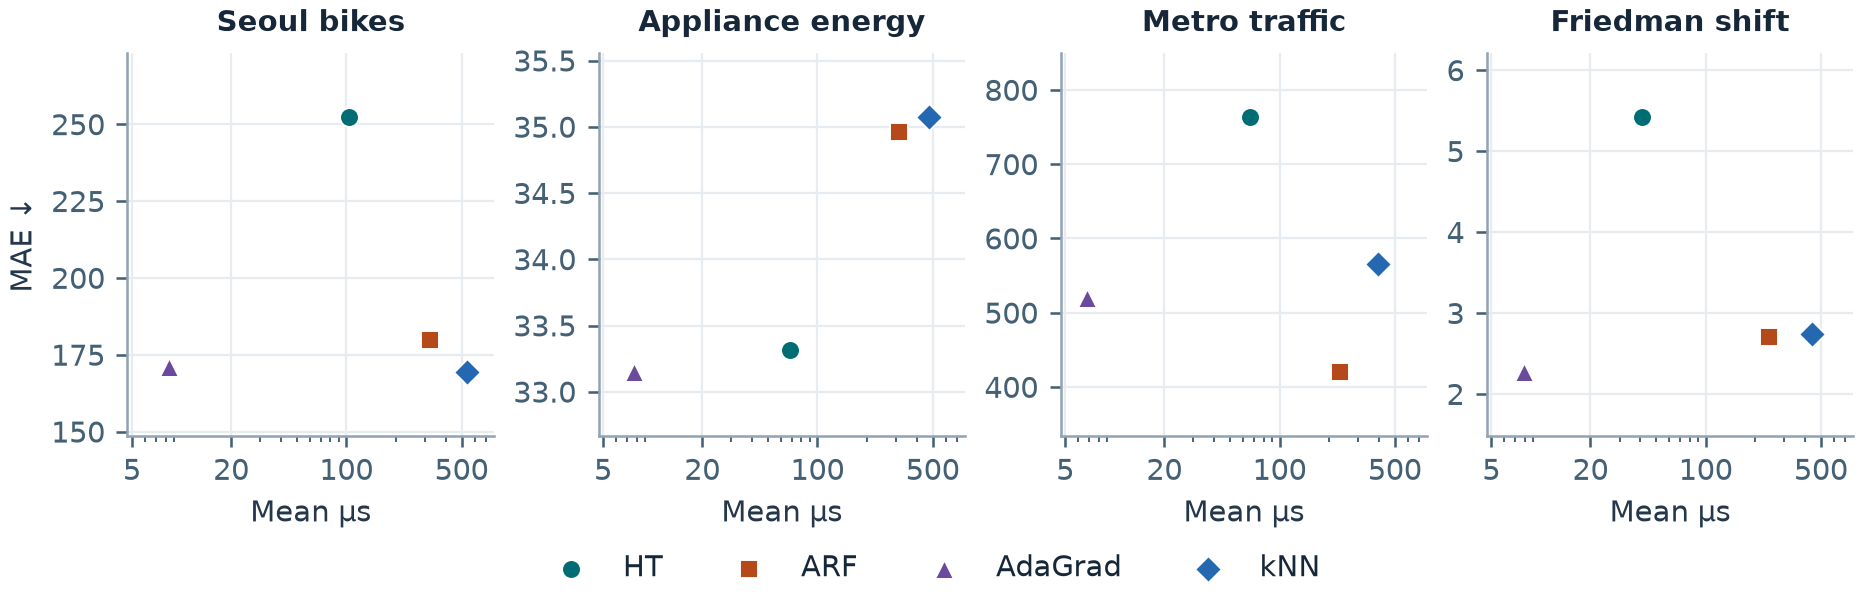

In [16]:
evaluate("regression", "River")
reg = read("river_regression")
display(reg[["stream", "model", "n", "mae", "rmse", "r2", "wall_s", "mean_us", "p95_us"]])
facet_tradeoff("regression")

### Regression drift

,stream,detector,policy,alarms,pre_change_alarms,delay,first_1000_after,score,mean_us
0,SeoulBikes,NaN,baseline,0,NaN,NaN,NaN,252.3206,103.8499
1,SeoulBikes,ADWIN,monitor,9,NaN,NaN,NaN,252.3206,106.6406
2,SeoulBikes,ADWIN,reset,10,NaN,NaN,NaN,270.9771,85.6442
3,SeoulBikes,PageHinkley,monitor,5,NaN,NaN,NaN,252.3206,105.2104
4,SeoulBikes,PageHinkley,reset,2,NaN,NaN,NaN,202.4628,91.4116
5,SeoulBikes,KSWIN,monitor,36,NaN,NaN,NaN,252.3206,237.5369
6,SeoulBikes,KSWIN,reset,44,NaN,NaN,NaN,354.9689,189.3808
7,ApplianceEnergy,NaN,baseline,0,NaN,NaN,NaN,33.3120,67.7262
8,ApplianceEnergy,ADWIN,monitor,7,NaN,NaN,NaN,33.3120,70.5711
9,ApplianceEnergy,ADWIN,reset,18,NaN,NaN,NaN,43.2322,62.9902


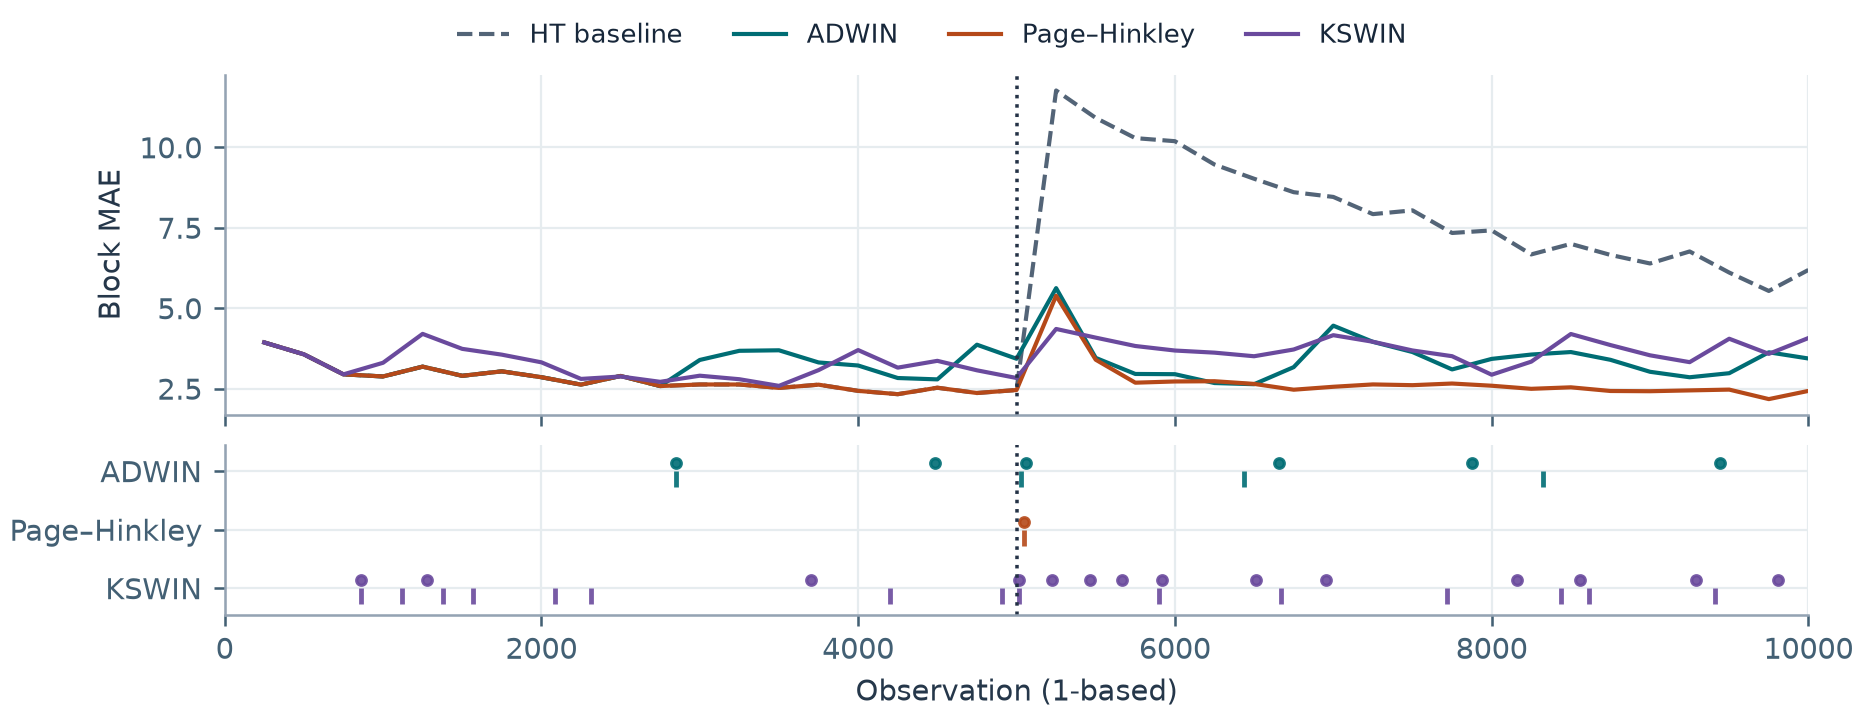

In [17]:
drift_columns = [
    "stream", "detector", "policy", "alarms", "pre_change_alarms",
    "delay", "first_1000_after", "score", "mean_us",
]
display(read("regression_drift")[drift_columns])
drift_figure("regression")

## 4. River classification

Compare a Hoeffding tree, an adaptive random forest, AdaGrad logistic regression, and Gaussian Naive Bayes. Macro F1 gives equal weight to each class.

River classification Occupancy, n=20560


River classification EEGEyeState, n=14980


River classification GasSensorDrift, n=5574


River classification SEAShift, n=10000


,stream,model,n,accuracy,macro_f1,kappa,wall_s,mean_us,p95_us,rss_peak_mib
0,Occupancy,HT,20560,0.9807,0.9736,0.9471,0.1521,7.0986,6.3330,276.1875
1,Occupancy,ARF,20560,0.9768,0.9676,0.9352,1.6629,79.7654,140.5000,276.4219
2,Occupancy,Logistic,20560,0.9668,0.9530,0.9061,0.1076,4.9331,5.0840,276.4219
3,Occupancy,GaussianNB,20560,0.9614,0.9479,0.8960,0.8320,39.7206,46.1670,276.4219
4,EEGEyeState,HT,14980,0.5852,0.5844,0.1717,0.2383,15.6035,13.3330,295.1562
5,EEGEyeState,ARF,14980,0.9678,0.9675,0.9349,1.0985,72.8113,108.3381,295.1875
6,EEGEyeState,Logistic,14980,0.9048,0.9037,0.8074,0.1297,8.3653,8.7500,295.1875
7,EEGEyeState,GaussianNB,14980,0.4741,0.3809,0.0350,0.7582,50.1424,56.9590,295.1875
8,GasSensorDrift,HT,5574,0.5531,0.5038,0.0652,0.0798,14.0195,10.6250,280.6094
9,GasSensorDrift,ARF,5574,0.8066,0.8040,0.6084,0.7434,132.6713,297.6001,280.6250


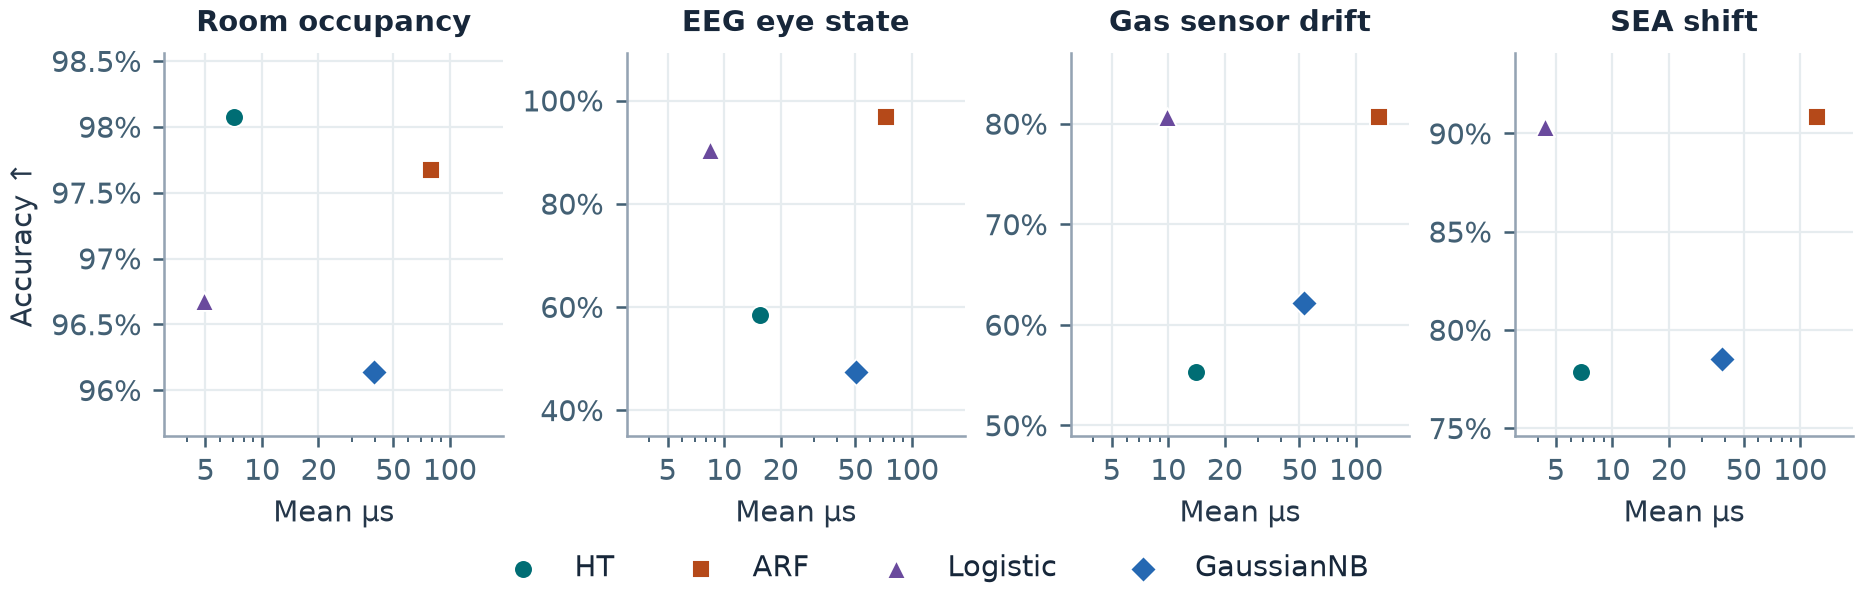

In [18]:
evaluate("classification", "River")
classification_columns = [
    "stream", "model", "n", "accuracy", "macro_f1", "kappa",
    "wall_s", "mean_us", "p95_us", "rss_peak_mib",
]
river = read("river_classification")
display(river[classification_columns])
facet_tradeoff("classification")

### Classification drift

Detection delays are evaluated only for the known synthetic shift. The expandable logs contain every alarm from the real and synthetic replays, in 1-based positions.

,stream,detector,policy,alarms,pre_change_alarms,delay,first_1000_after,score,mean_us
0,Occupancy,NaN,baseline,0,NaN,NaN,NaN,0.9807,7.0986
1,Occupancy,ADWIN,monitor,6,NaN,NaN,NaN,0.9807,9.0120
2,Occupancy,ADWIN,reset,30,NaN,NaN,NaN,0.9559,7.0765
3,Occupancy,DDM,monitor,2,NaN,NaN,NaN,0.9807,7.4930
4,Occupancy,DDM,reset,35,NaN,NaN,NaN,0.9828,5.8048
5,Occupancy,EDDM,monitor,5,NaN,NaN,NaN,0.9807,7.2670
6,Occupancy,EDDM,reset,21,NaN,NaN,NaN,0.9664,5.7868
7,Occupancy,HDDM_A,monitor,13,NaN,NaN,NaN,0.9807,18.0582
8,Occupancy,HDDM_A,reset,45,NaN,NaN,NaN,0.9853,17.2589
9,EEGEyeState,NaN,baseline,0,NaN,NaN,NaN,0.5852,15.6035


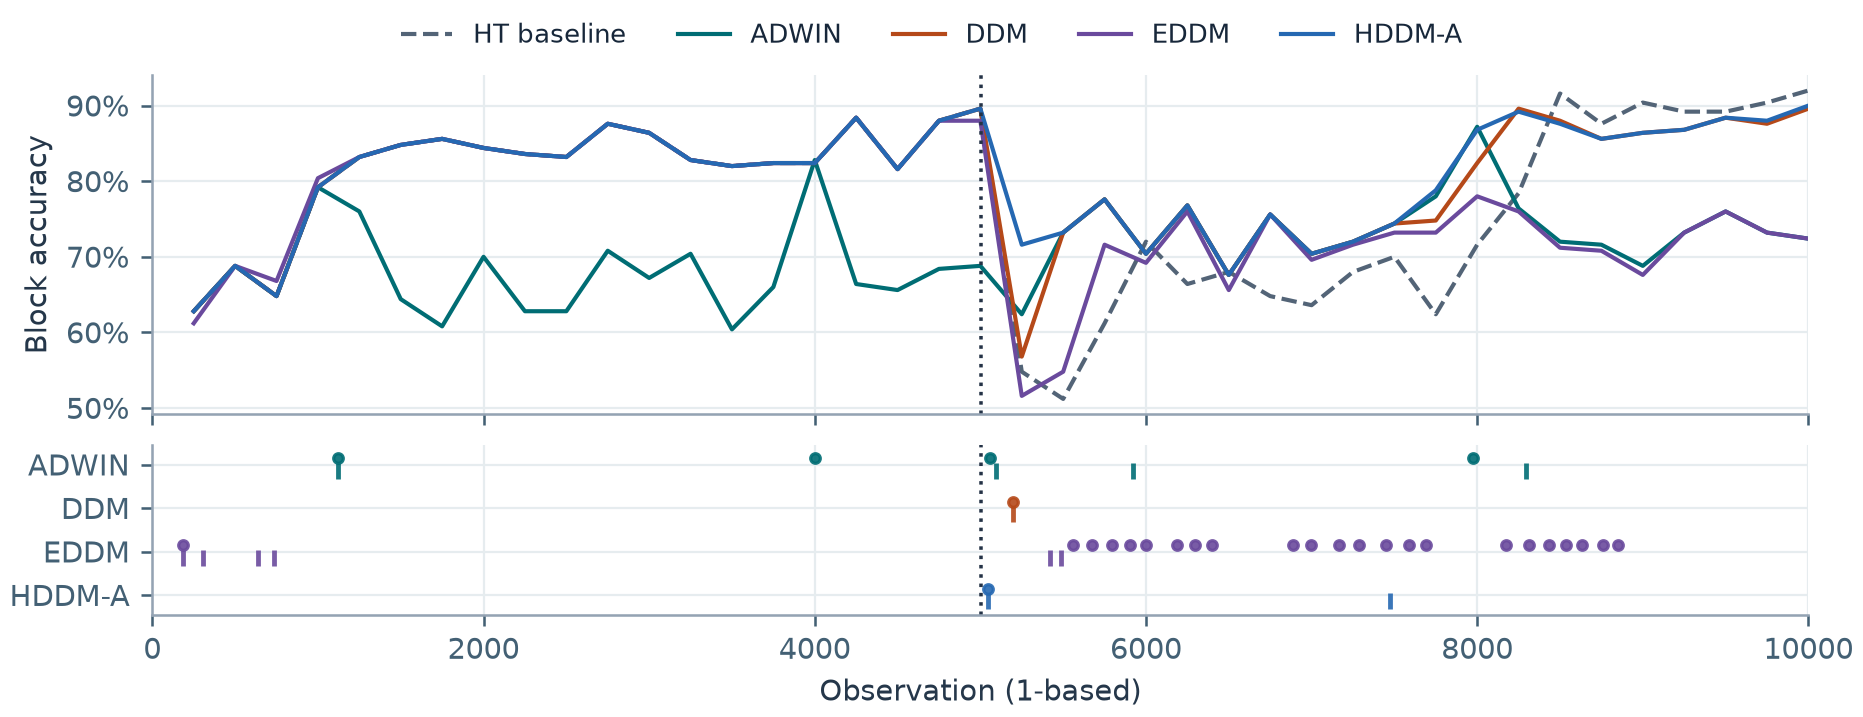

In [19]:
display(read("classification_drift")[drift_columns])
drift_figure("classification")

In [20]:
from html import escape

for task in ("regression", "classification"):
    alarms = read(f"{task}_alarms")
    groups = []
    for (stream, detector, policy), rows in alarms.groupby(["stream", "detector", "policy"]):
        label = escape(f"{SHORT.get(stream, stream)} · {detector} · {policy}")
        positions = ", ".join(map(str, rows.position))
        groups.append(f"<p><strong>{label}</strong><br>{positions}</p>")
    title = f"{task.capitalize()} alarm positions (1-based)"
    display(HTML(f"<details><summary>{title}</summary>{''.join(groups)}</details>"))

## 5. CapyMOA comparison

Start the JVM here, after the River benchmarks. Use the same rows, seeds, and comparable tree and forest settings. CapyMOA uses inverse-scaling SGD with log loss as its closest counterpart to River's AdaGrad logistic regression.

In [21]:
from math import sqrt

from capymoa.base import MOAClassifier
from capymoa.classifier import HoeffdingTree, NaiveBayes, SGDClassifier
from capymoa.core import LabeledInstance
from capymoa.stream import Schema
from moa.classifiers.meta import AdaptiveRandomForest


def classification_schema(rows, name):
    return Schema.from_custom(
        features=[*rows[0][0], "class"], target="class",
        categories={"class": ["0", "1"]}, name=name,
    )


def capy_rows(rows, schema, feature_names):
    return [
        (LabeledInstance.from_array(schema, np.array([x[key] for key in feature_names]), y), y)
        for x, y in rows
    ]


def capy_classification_models(schema, seed, n_features):
    # MOA mode 0 takes m literally. River's "sqrt" rounds before choosing m.
    max_features = round(sqrt(n_features))
    return {
        "HT": lambda: HoeffdingTree(
            schema, random_seed=seed, grace_period=100, confidence=1e-5,
            tie_threshold=.05, leaf_prediction="MajorityClass", disable_prepruning=False,
        ),
        "ARF": lambda: MOAClassifier(
            moa_learner=AdaptiveRandomForest, schema=schema, random_seed=seed, CLI=(
                "-l (ARFHoeffdingTree -g 100 -c 1e-5 -t 0.05 -l MC) "
                f"-s 5 -o 0 -m {max_features} -a 6 "
                "-x (ADWINChangeDetector -a 0.001) -p (ADWINChangeDetector -a 0.01) -j 1"
            ),
        ),
        "Logistic": lambda: SGDClassifier(
            schema, loss="log_loss", learning_rate="invscaling", eta0=.05, random_seed=seed,
        ),
        "GaussianNB": lambda: NaiveBayes(schema, random_seed=seed),
    }

In [22]:
def cross_library():
    river = read("river_classification")
    capy = read("capymoa_classification")
    data = river.merge(capy, on=["stream", "model"], suffixes=("_river", "_capy"))
    fig, axes = plt.subplots(1, 4, sharex=True, sharey=True, figsize=(8.1, 2.68), layout="constrained")
    for ax, (name, d) in zip(axes, data.groupby("stream", sort=False), strict=True):
        ax.axvline(1, color="#52677b", linestyle=":", linewidth=1)
        ax.axhline(0, color="#52677b", linestyle=":", linewidth=1)
        for row, color, marker in zip(d.itertuples(), PALETTE[:4], ("o", "s", "^", "D"), strict=True):
            ax.scatter(row.mean_us_river / row.mean_us_capy,
                       100 * (row.accuracy_capy - row.accuracy_river),
                       color=color, marker=marker, s=34, label=row.model, zorder=3)
        ax.set_xscale("log")
        ax.set_title(SHORT.get(name, name), fontsize=9)
    axes[0].set_ylabel("CapyMOA − River (pp)")
    fig.supxlabel("River / CapyMOA mean latency (>1 favors CapyMOA)", fontsize=8.5)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncols=4)
    save(fig, "cross_library")

CapyMOA classification Occupancy, n=20560


CapyMOA classification EEGEyeState, n=14980


CapyMOA classification GasSensorDrift, n=5574


CapyMOA classification SEAShift, n=10000


,stream,model,n,accuracy,macro_f1,kappa,wall_s,mean_us,p95_us,rss_peak_mib
0,Occupancy,HT,20560,0.9805,0.9732,0.9465,0.4493,21.5254,24.7500,419.2969
1,Occupancy,ARF,20560,0.9636,0.9494,0.8989,0.6725,32.3623,34.5020,508.4375
2,Occupancy,Logistic,20560,0.9344,0.9138,0.8281,6.6214,321.4184,363.7910,506.5469
3,Occupancy,GaussianNB,20560,0.9604,0.9467,0.8935,0.3175,15.1271,15.8330,508.6250
4,EEGEyeState,HT,14980,0.5640,0.5630,0.1286,0.2925,19.1979,20.7920,536.1562
5,EEGEyeState,ARF,14980,0.9627,0.9623,0.9246,0.4952,32.7346,31.4160,536.3906
6,EEGEyeState,Logistic,14980,0.5649,0.5639,0.1472,4.8409,322.5403,367.4580,536.4062
7,EEGEyeState,GaussianNB,14980,0.4742,0.3810,0.0351,0.2357,15.4355,16.6250,536.4062
8,GasSensorDrift,HT,5574,0.5531,0.5038,0.0652,0.0909,15.9938,16.5414,517.7344
9,GasSensorDrift,ARF,5574,0.8249,0.8242,0.6486,0.2265,40.2608,116.3624,517.7500


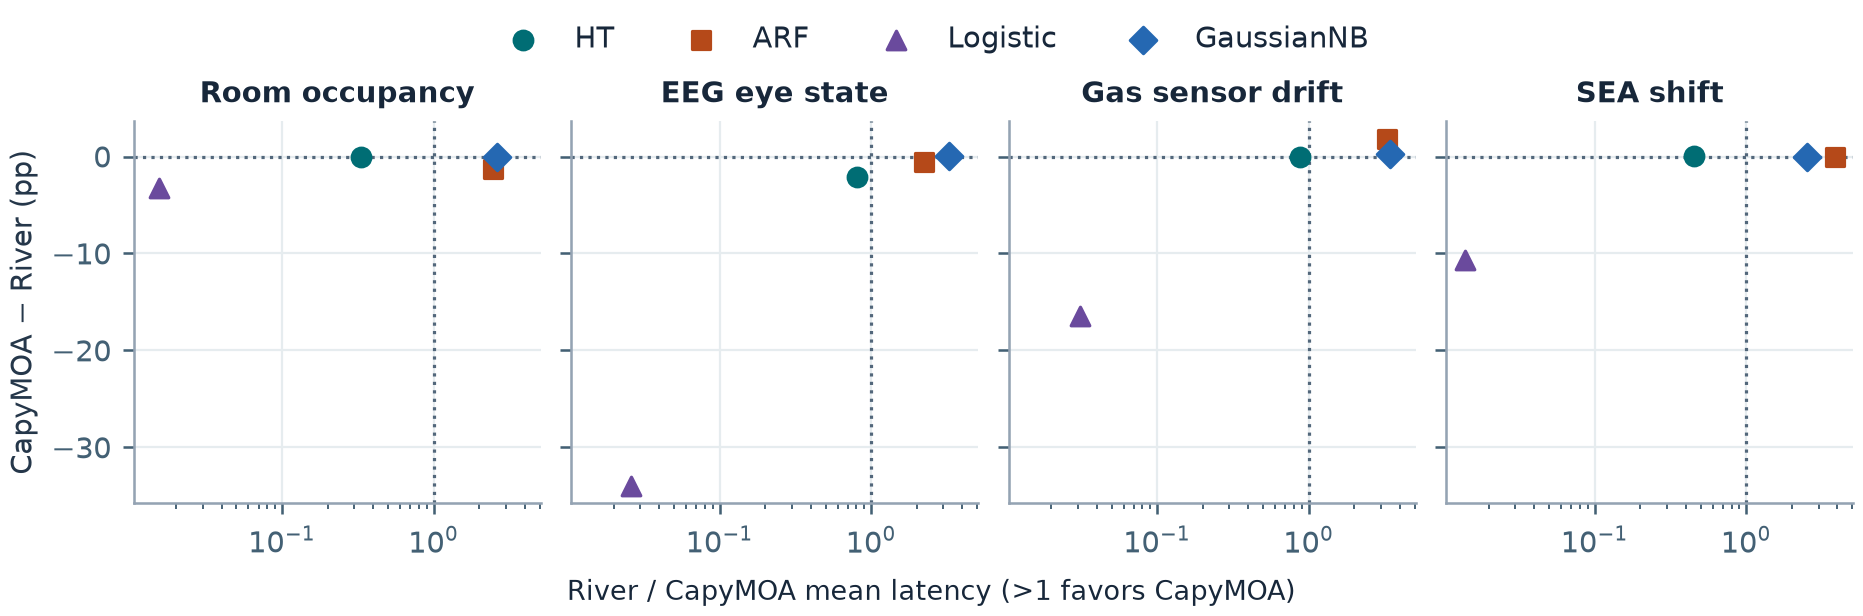

In [23]:
evaluate("classification", "CapyMOA")
capy = read("capymoa_classification")
display(capy[classification_columns])
cross_library()

## 6. CapyMOA stream clustering

Score each block using the previous block's centers. Score agreement with held-back occupancy labels or simulated group IDs using adjusted Rand index (ARI).

In [24]:
from capymoa.cluster import ClusTree, Clustream_with_kmeans, Denstream_with_dbscan
from sklearn.metrics import adjusted_rand_score

CLUSTER_BLOCK = 250
CLUSTER_SWITCH = 3001


def get_centers(model):
    # The wrapper drops the final coordinate unconditionally and calls the
    # Java snapshot repeatedly. Fetch one snapshot and check its dimensionality.
    snapshot = (model.moa_learner.getClusteringResult() if model.implements_macro_clusters()
                else model.moa_learner.getMicroClusteringResult())
    centers = []
    if snapshot is not None:
        for item in snapshot.getClustering():
            center = np.array(item.getCenter())
            if len(center) not in (2, 3):
                raise ValueError(f"Unexpected cluster center dimensions: {len(center)}")
            if np.isfinite(center[:2]).all():
                centers.append(center[:2])
    return np.array(centers).reshape(-1, 2)


def run_clustering():
    schema = Schema.from_custom(
        ["x1", "x2", "dummy"], target="dummy",
        categories={"dummy": ["unused"]}, name="Clustering",
    )
    methods = {
        "CluStream": lambda k: Clustream_with_kmeans(
            schema, time_window=750, max_num_kernels=30, k_option=k,
        ),
        "DenStream": lambda _k: Denstream_with_dbscan(
            schema, horizon=750, epsilon=.55, beta=.2, mu=2, init_points=300,
            lambda_option=.25, speed=100,
        ),
        "ClusTree": lambda _k: ClusTree(schema, horizon=750, max_height=5),
    }
    summary, blocks, snapshots = [], [], []
    datasets = (
        ("OccupancySensors", 2, occupancy_clustering()),
        ("GaussianShift", 3, clustering_rows(moving=True)),
    )
    for stream, k, (x, hidden) in datasets:
        moving = stream == "GaussianShift"
        # Constant dummy class makes the Java header valid without revealing hidden labels.
        rows = [LabeledInstance.from_array(schema, point, 0) for point in x]
        for name, factory in methods.items():
            print(f"CapyMOA clustering {stream} {name}", flush=True)
            model = factory(k)
            identifiers = {"stream": stream, "model": name}
            fit_ns = np.empty(len(x))
            query_ns, ari_history = [], []
            centers = np.empty((0, 2))
            start = perf_counter_ns()
            for offset in range(0, len(x), CLUSTER_BLOCK):
                end = offset + CLUSTER_BLOCK
                ari, mean_distance = np.nan, np.nan
                # A snapshot from the previous block is used before any update on this block.
                if len(centers):
                    dist = np.linalg.norm(x[offset:end, None] - centers, axis=2)
                    nearest = dist.argmin(axis=1)
                    ari = adjusted_rand_score(hidden[offset:end], nearest)
                    mean_distance = dist.min(axis=1).mean()
                blocks.append(identifiers | {
                    "start": offset + 1, "end": end, "centers": len(centers),
                    "ari": ari, "mean_distance": mean_distance,
                })
                ari_history.append(ari)
                for i in range(offset, end):
                    tick = perf_counter_ns()
                    model.train(rows[i])
                    fit_ns[i] = perf_counter_ns() - tick
                tick = perf_counter_ns()
                centers = get_centers(model)
                query_ns.append(perf_counter_ns() - tick)
                snapshots.extend(identifiers | {"end": end, "x1": a, "x2": b} for a, b in centers)
            elapsed = (perf_counter_ns() - start) / 1e9
            summary.append(identifiers | {
                "n": len(x), "mean_ari": np.nanmean(ari_history),
                "scored_blocks": int(np.isfinite(ari_history).sum()),
                "first_post_shift_ari": ari_history[(CLUSTER_SWITCH - 1) // CLUSTER_BLOCK] if moving else "",
                "last_4_blocks_ari": np.nanmean(ari_history[-4:]), "final_centers": len(centers),
                "wall_s": elapsed, "mean_train_us": fit_ns.mean() / 1e3,
                "p95_train_us": np.quantile(fit_ns, .95) / 1e3,
                "mean_snapshot_ms": np.mean(query_ns) / 1e6,
            })
    write_table("clustering", summary)
    write_table("clustering_blocks", blocks)
    write_table("clustering_centers", snapshots)

In [25]:
def clustering():
    data = read("clustering_blocks")
    fig, axes = plt.subplots(1, 2, sharey=True, figsize=(8.1, 2.45), layout="constrained")
    for ax, (name, d) in zip(axes, data.groupby("stream", sort=False), strict=True):
        for (model, rows), color in zip(d.groupby("model", sort=False), PALETTE):
            ax.plot(rows.start, rows.ari, color=color, label=model, marker=".", markersize=3)
        if name == "GaussianShift":
            ax.axvline(3001, color="#243246", linestyle=":", linewidth=1.1)
        ax.set_title(SHORT[name], fontsize=9)
        ax.set_xlabel("Scored block start")
        ax.set_ylim(min(-.04, float(data.ari.min()) - .03), 1.04)
    axes[0].set_ylabel("Adjusted Rand index")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncols=3)
    save(fig, "clustering")

    data = read("clustering_centers")
    moving = data[(data.stream == "GaussianShift") & data.end.isin([3000, 3500, 6000])]
    fig, axes = plt.subplots(1, 3, figsize=(8.1, 2.35), sharex=True, sharey=True, layout="constrained")
    for ax, (end, snapshots) in zip(axes, moving.groupby("end"), strict=True):
        for (model, d), color, marker in zip(
            snapshots.groupby("model", sort=False), PALETTE, ("o", "^", "+"),
        ):
            ax.scatter(d.x1, d.x2, label=model, color=color, marker=marker, s=19, alpha=.85)
        ax.set_title(f"After {end:,} observations", fontsize=8.7)
        ax.set_xlabel("Feature 1")
        ax.set_aspect("equal")
    axes[0].set_ylabel("Feature 2")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncols=3)
    save(fig, "cluster_centers")

CapyMOA clustering OccupancySensors CluStream


CapyMOA clustering OccupancySensors DenStream


CapyMOA clustering OccupancySensors ClusTree


CapyMOA clustering GaussianShift CluStream


CapyMOA clustering GaussianShift DenStream


CapyMOA clustering GaussianShift ClusTree


,stream,model,n,mean_ari,scored_blocks,first_post_shift_ari,last_4_blocks_ari,final_centers,wall_s,mean_train_us,p95_train_us,mean_snapshot_ms
0,OccupancySensors,CluStream,6000,0.8072,23,NaN,0.8189,2,0.1604,24.0955,23.9170,0.2177
1,OccupancySensors,DenStream,6000,0.7916,22,NaN,0.8306,2,0.8814,82.6421,122.2080,15.5774
2,OccupancySensors,ClusTree,6000,0.4176,23,NaN,0.3358,14,0.0502,5.5819,7.0420,0.2471
3,GaussianShift,CluStream,6000,0.8312,23,0.8987,0.7301,3,0.1600,24.2674,24.3771,0.1487
4,GaussianShift,DenStream,6000,0.7291,22,0.5852,1.0000,3,0.4114,45.6012,67.9601,5.3125
5,GaussianShift,ClusTree,6000,0.3275,23,0.7811,0.4423,15,0.1006,10.4726,5.3330,0.7432


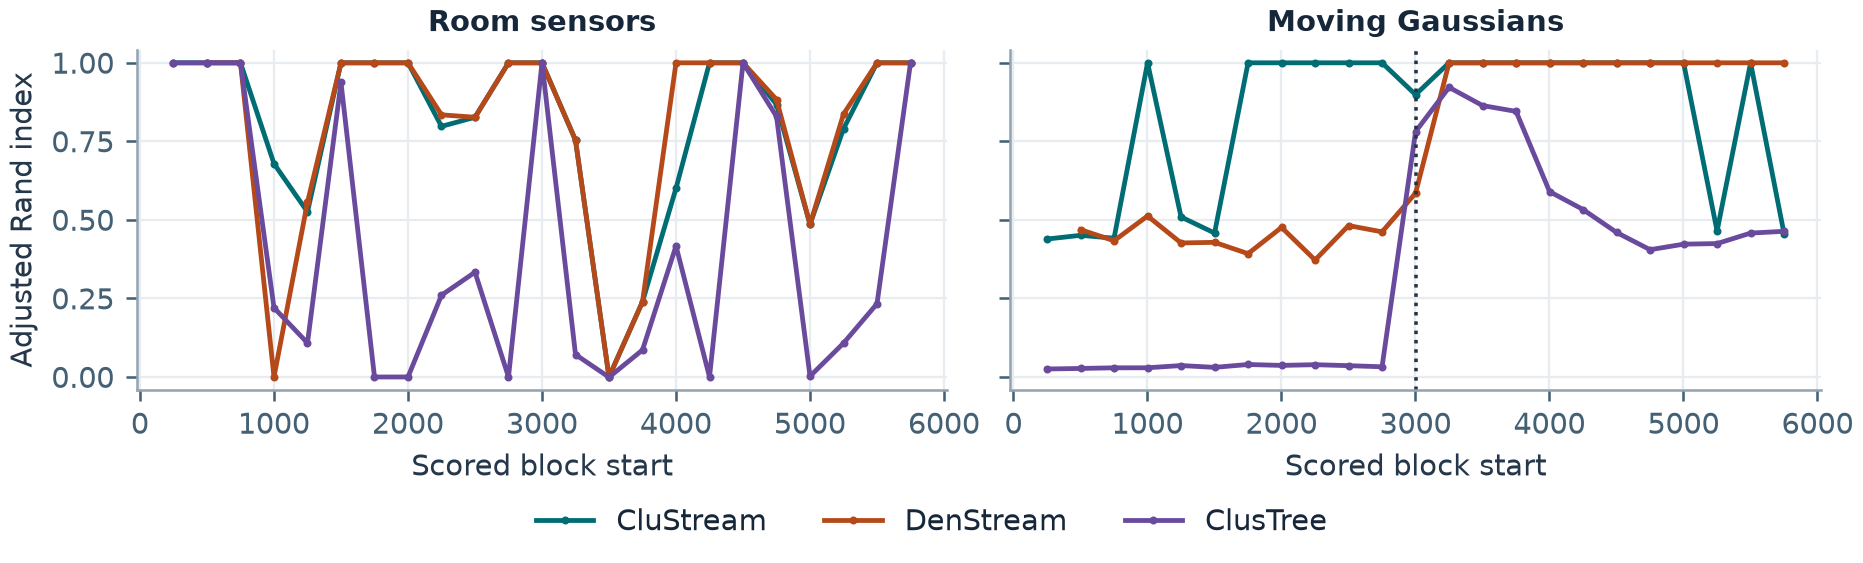

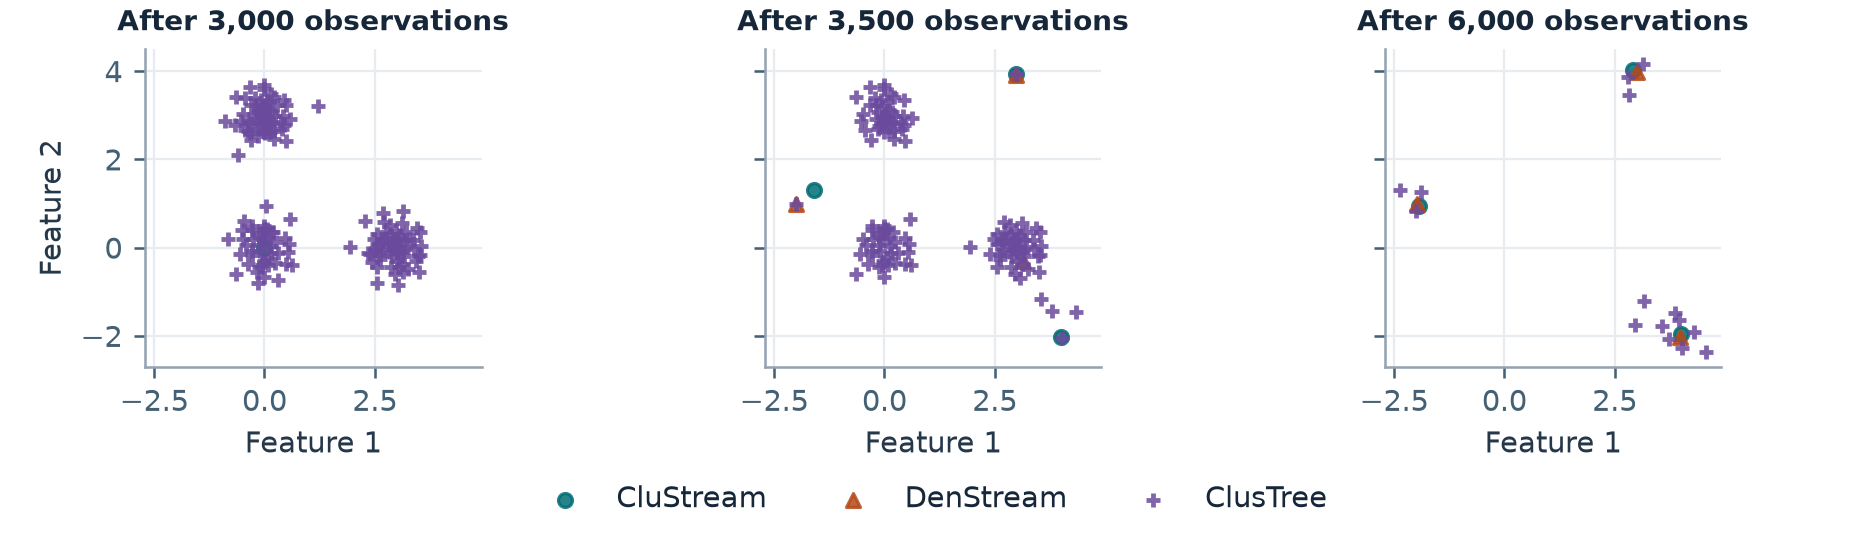

In [26]:
run_clustering()
display(read('clustering'))
clustering()

## 7. Bonus · Online model selection

On SEA, compare epsilon-greedy bandit selection, successive halving, and AutoClass against fixed Hoeffding and Hoeffding Adaptive Trees. The post-shift score covers the first 1,000 rows from the true change.

In [27]:
import json
import random
from tempfile import TemporaryDirectory

from capymoa.automl import AutoClass, BanditClassifier, EpsilonGreedy, SuccessiveHalvingClassifier
from capymoa.classifier import HoeffdingAdaptiveTree

autoclass_settings = {'windowSize': 500,
 'ensembleSize': 5,
 'newConfigurations': 3,
 'keepCurrentModel': True,
 'lambda': 0.05,
 'preventAlgorithmDeath': True,
 'keepGlobalIncumbent': True,
 'keepAlgorithmIncumbents': True,
 'keepInitialConfigurations': True,
 'useTestEnsemble': True,
 'resetProbability': 0.01,
 'numberOfCores': 1,
 'performanceMeasureMaximisation': True,
 'algorithms': [{'algorithm': 'moa.classifiers.trees.HoeffdingTree',
                 'parameters': [{'parameter': 'g',
                                 'type': 'integer',
                                 'value': 100,
                                 'range': [50, 200]},
                                {'parameter': 'c',
                                 'type': 'float',
                                 'value': 0.001,
                                 'range': [1e-05, 0.01]}]},
                {'algorithm': 'moa.classifiers.trees.HoeffdingAdaptiveTree',
                 'parameters': [{'parameter': 'g',
                                 'type': 'integer',
                                 'value': 100,
                                 'range': [50, 200]},
                                {'parameter': 'c',
                                 'type': 'float',
                                 'value': 0.001,
                                 'range': [1e-05, 0.01]}]}]}

In [28]:
def run_automl(configuration):
    stream = "SEAShift"
    rows = load_rows(stream)
    y = np.array([label for _, label in rows])
    schema = classification_schema(rows, stream)
    feature_names = tuple(rows[0][0])
    classes = (HoeffdingTree, HoeffdingAdaptiveTree)

    def candidates():
        return [cls(schema, random_seed=SEED, grace_period=grace)
                for cls in classes for grace in (50, 100, 200)]

    methods = {
        "HT (g=100)": lambda: HoeffdingTree(schema, random_seed=SEED, grace_period=100),
        "HAT (g=100)": lambda: HoeffdingAdaptiveTree(schema, random_seed=SEED, grace_period=100),
        "Bandit": lambda: BanditClassifier(
            schema=schema, random_seed=SEED, base_classifiers=candidates(),
            policy=EpsilonGreedy(epsilon=.15, burn_in=300),
        ),
        "Successive halving": lambda: SuccessiveHalvingClassifier(
            schema=schema, random_seed=SEED, base_classifiers=candidates(),
            budget=10_000, eta=2., min_models=1,
        ),
        "AutoClass": lambda: AutoClass(
            schema=schema, random_seed=SEED,
            configuration_json=str(configuration),
            base_classifiers=list(classes),
        ),
    }
    summary, blocks = [], []
    for name, factory in methods.items():
        print(f"CapyMOA AutoML {name}", flush=True)
        random.seed(SEED)
        pred, cost, _ = measure(
            capy_rows(rows, schema, feature_names), factory, "classification", capy=True,
        )
        identifiers = {"stream": stream, "model": name}
        summary.append(identifiers | classification_scores(y, pred) | {
            "n": len(y),
            "first_1000_after": np.mean(y[SWITCH - 1:SWITCH + 999] == pred[SWITCH - 1:SWITCH + 999]),
        } | cost)
        blocks.extend(score_blocks(y, pred, "classification", identifiers))
    write_table("automl", summary)
    write_table("automl_blocks", blocks)

In [29]:
def automl():
    data = read("automl_blocks")
    fig, ax = plt.subplots(figsize=(8.1, 2.65), layout="constrained")
    for i, ((model, rows), color) in enumerate(zip(data.groupby("model", sort=False), PALETTE, strict=True)):
        ax.plot(rows.end, rows.score, label=model, color=color, linewidth=1.45,
                linestyle="--" if i < 2 else "-")
    ax.axvline(5001, color="#243246", linestyle=":", linewidth=1.1)
    ax.set(xlabel="Observation (1-based)", ylabel="Block accuracy", xlim=(0, 10000))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncols=5, fontsize=8)
    save(fig, "automl")

CapyMOA AutoML HT (g=100)


CapyMOA AutoML HAT (g=100)


CapyMOA AutoML Bandit


CapyMOA AutoML Successive halving


CapyMOA AutoML AutoClass


,model,accuracy,macro_f1,kappa,first_1000_after,wall_s,mean_us,p95_us
0,HT (g=100),0.8225,0.8222,0.6491,0.5580,0.1655,16.1985,18.4160
1,HAT (g=100),0.8934,0.8931,0.7862,0.7600,0.1898,18.6162,22.5000
2,Bandit,0.8132,0.8128,0.6308,0.5650,31.1963,"3,118.9246","3,322.9202"
3,Successive halving,0.8924,0.8921,0.7842,0.7600,34.1116,"3,410.4144","11,474.0830"
4,AutoClass,0.9055,0.9052,0.8104,0.8090,0.5668,56.2701,45.4211


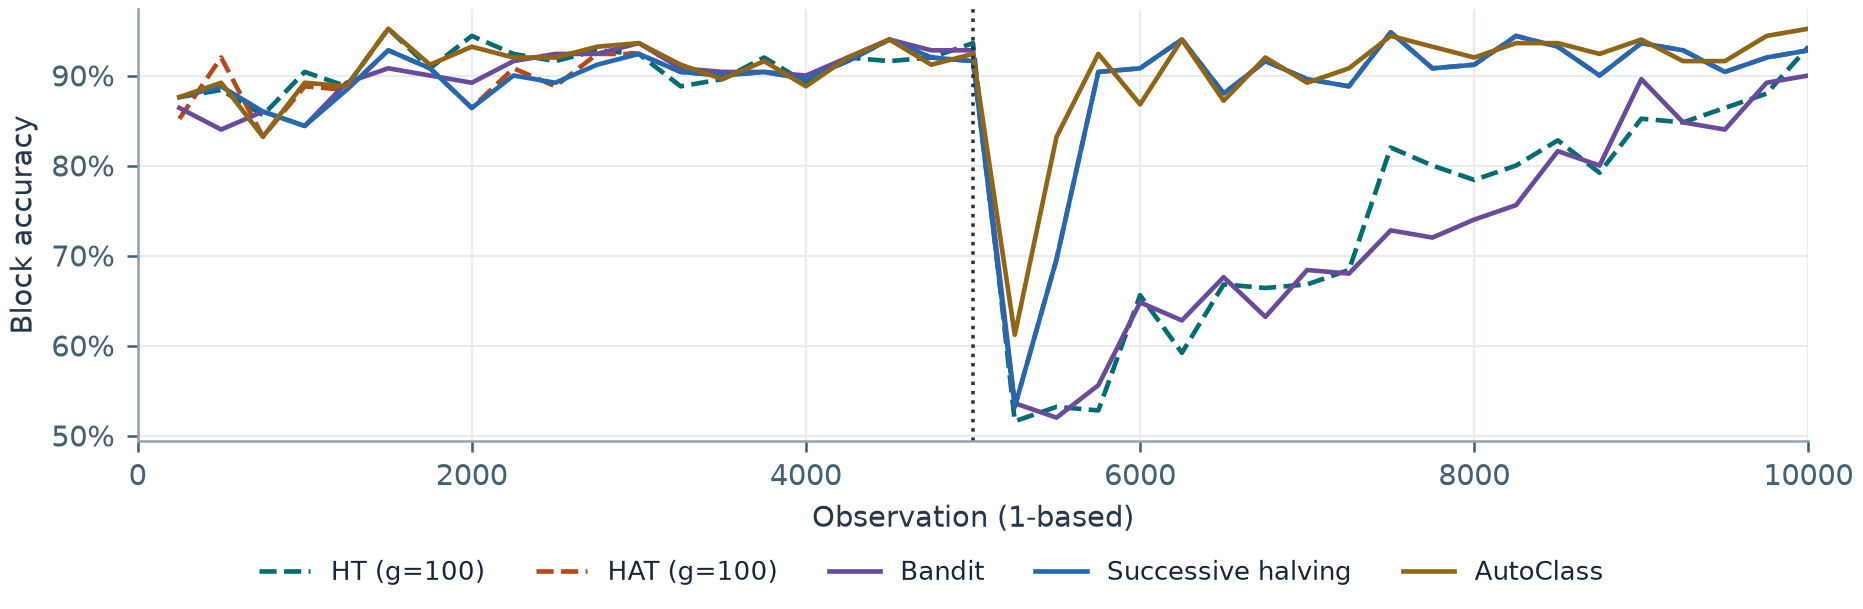

In [30]:
# AutoClass accepts its settings as a JSON file.
with TemporaryDirectory(prefix="lab4-autoclass-") as directory:
    configuration = Path(directory) / "autoclass.json"
    configuration.write_text(json.dumps(autoclass_settings), encoding="utf-8")
    run_automl(configuration)

display(read("automl")[[
    "model", "accuracy", "macro_f1", "kappa",
    "first_1000_after", "wall_s", "mean_us", "p95_us",
]])
automl()